In [25]:
import nltk
nltk.download('all')

[nltk_data] Downloading collection 'all'
[nltk_data]    | 
[nltk_data]    | Downloading package abc to /root/nltk_data...
[nltk_data]    |   Package abc is already up-to-date!
[nltk_data]    | Downloading package alpino to /root/nltk_data...
[nltk_data]    |   Package alpino is already up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger is already up-
[nltk_data]    |       to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_eng to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger_eng is already
[nltk_data]    |       up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_ru to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger_ru is already
[nltk_data]    |       up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_r

True

In [26]:
import re
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')
import spacy
nlp = spacy.load('en_core_web_sm')
import wordcloud
import string
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize,word_tokenize
from nltk.stem.porter import PorterStemmer
from nltk.stem import WordNetLemmatizer
import matplotlib.pyplot as plt

In [27]:
df = pd.read_csv(r'/content/apple.txt',on_bad_lines='skip')
df.head()

,x
0,It's amazing..... battery last around 10 -12 h...
1,Finally a MacBook possession. Got it in 50k in...
2,Best Laptop under 60k. If you don't want any a...
3,Pros:1. Light weight and super fast response t...
4,""""


In [28]:
df.shape

(40, 1)

In [29]:
df1 = [i.strip() for i in df.x]

* The text data consisting of the uncessary spaces after the line compeltion and in btw to remove them we use a function called strip which removes the uncessary spaces.

In [30]:
df1

["It's amazing..... battery last around 10 -12 hrs.....best laptop for students and coders",
 "Finally a MacBook possession. Got it in 50k in Diwali sale. Technically good laptop.Good News.luxury product, niche technology, good battery life, reliable machine (other laptops crash and become defunct in 6-10 years), no anti-virus required, security of data and transactions much better. Terrific sense of possession & pride.Bad News. Problems will be there if you are switching from windows based system - very less space in hard disk, no CD drive, inability to transfer data from Mac to your existing external hard disc unless you format it, apps are mostly paid and re unreasonably expensive (no free apps which are available otherwise on google play store, even the angry bird costs Rs 400 !!), all printers are not compatible (e.g. the most economical MFD laser printer RICOH SP 111 can't be used), huge compatibility issues with Pages (MS Word) and Keynote (powerpoint) unless you master it by wo

In [31]:
text = ' '.join(df1)

In [32]:
text

'It\'s amazing..... battery last around 10 -12 hrs.....best laptop for students and coders Finally a MacBook possession. Got it in 50k in Diwali sale. Technically good laptop.Good News.luxury product, niche technology, good battery life, reliable machine (other laptops crash and become defunct in 6-10 years), no anti-virus required, security of data and transactions much better. Terrific sense of possession & pride.Bad News. Problems will be there if you are switching from windows based system - very less space in hard disk, no CD drive, inability to transfer data from Mac to your existing external hard disc unless you format it, apps are mostly paid and re unreasonably expensive (no free apps which are available otherwise on google play store, even the angry bird costs Rs 400 !!), all printers are not compatible (e.g. the most economical MFD laser printer RICOH SP 111 can\'t be used), huge compatibility issues with Pages (MS Word) and Keynote (powerpoint) unless you master it by worki

* To check the sentiment for every lines we need to seprate every line into different different lines.
* To do that we used join function which will make evry sentences into single paragraph. so we can seprate them afterwards.

In [33]:
doc = nlp(text)

In [34]:
spacy.displacy.render(doc,style='ent')

In [35]:
from wordcloud import WordCloud, STOPWORDS

In [36]:
word_cld = WordCloud(width=1000,height=1000,
                     background_color='white').generate(text)
word_cld

In [37]:
def wordcloud(data):
  plt.figure(figsize=(10,10))
  plt.imshow(data)
  plt.axis('off')
  plt.savefig('wordcloud.jpeg')

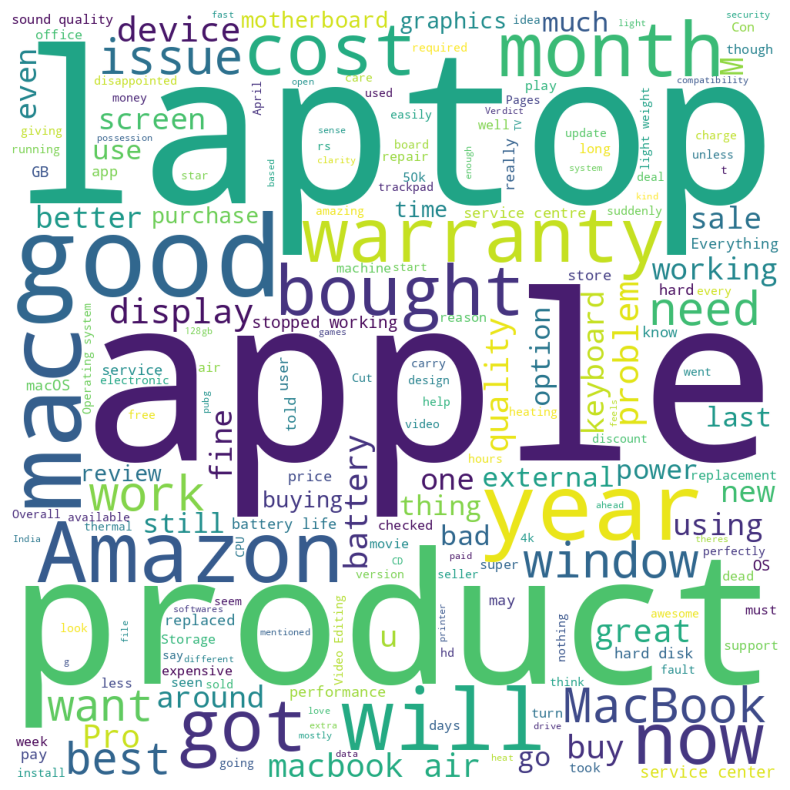

In [38]:
wordcloud(word_cld)

## Lexicon Based Approach:
* Affin Database:

In [39]:
sent_df=pd.DataFrame(sent_tokenize(text),columns=['sentence'])
sent_df.head()

,sentence
0,It's amazing..... battery last around 10 -12 h...
1,Got it in 50k in Diwali sale.
2,Technically good laptop.Good News.luxury produ...
3,Terrific sense of possession & pride.Bad News.
4,Problems will be there if you are switching fr...


* Now are all sentences are seprated and converted into dataframe foramt,

In [40]:
sent_df.shape

(188, 1)

In [41]:
aff= pd.read_csv(r'/content/Afinn.csv',encoding='latin1')

In [42]:
aff.head()

,word,value
0,abandon,-2
1,abandoned,-2
2,abandons,-2
3,abducted,-2
4,abduction,-2


In [43]:
aff_dict = aff.set_index('word')['value'].to_dict()
aff_dict

{'abandon': -2,
 'abandoned': -2,
 'abandons': -2,
 'abducted': -2,
 'abduction': -2,
 'abductions': -2,
 'abhor': -3,
 'abhorred': -3,
 'abhorrent': -3,
 'abhors': -3,
 'abilities': 2,
 'ability': 2,
 'aboard': 1,
 'absentee': -1,
 'absentees': -1,
 'absolve': 2,
 'absolved': 2,
 'absolves': 2,
 'absolving': 2,
 'absorbed': 1,
 'abuse': -3,
 'abused': -3,
 'abuses': -3,
 'abusive': -3,
 'accept': 1,
 'accepted': 1,
 'accepting': 1,
 'accepts': 1,
 'accident': -2,
 'accidental': -2,
 'accidentally': -2,
 'accidents': -2,
 'accomplish': 2,
 'accomplished': 2,
 'accomplishes': 2,
 'accusation': -2,
 'accusations': -2,
 'accuse': -2,
 'accused': -2,
 'accuses': -2,
 'accusing': -2,
 'ache': -2,
 'achievable': 1,
 'aching': -2,
 'acquit': 2,
 'acquits': 2,
 'acquitted': 2,
 'acquitting': 2,
 'acrimonious': -3,
 'active': 1,
 'adequate': 1,
 'admire': 3,
 'admired': 3,
 'admires': 3,
 'admiring': 3,
 'admit': -1,
 'admits': -1,
 'admitted': -1,
 'admonish': -2,
 'admonished': -2,
 'adopt': 

* Here we are converted aff dataset to dictonary the words column is assigned as key and value column is assgined as key's value.
* Because when we get the simmilar word in the data set directly we will get values if the key is not present it will return as zero.

In [44]:
aff_dict.get('TajMahal',0)

0

In [46]:
aff_dict.get('sad',0)

-2

In [52]:
def aff_sent(text:str=None):
  sent_ct=0
  if text:
    doc = nlp(text)
    for token in doc:
      sent_ct+= aff_dict.get(token.lemma_,0)
  if sent_ct>0:
    return 'Positive'
  elif sent_ct<0:
    return 'Negative'
  else:
    return 'Neutral'

In [53]:
aff_sent('Today im happy becuase you taken ur time for seeing My work ')

'Positive'

* Here we above return the function beacuse our affin and the data are in different. The above function will calculate the sentiment.
* First we are given condition that the text should be in the quote.
* so the sent varible get the sentence and it pass to spacy varible called doc. Now to our sentnce the spacy is applied because we need to calculate the lemtization and through looping we are checking through the lemmatization and each word values are added if the word is negative the condition matching will be given as output.

In [50]:
sent_df['word_count']= sent_df.sentence.str.split().apply(len)
sent_df.head()

,sentence,word_count
0,It's amazing..... battery last around 10 -12 h...,17
1,Got it in 50k in Diwali sale.,7
2,Technically good laptop.Good News.luxury produ...,31
3,Terrific sense of possession & pride.Bad News.,7
4,Problems will be there if you are switching fr...,65


* The above code will create one more column and it will hold the information of how many words are in each sentnces.
* It splits wherever it has space after evry space everything considered as word.

In [54]:
sent_df['aff_sent']= sent_df.sentence.apply(lambda x: aff_sent(x))
sent_df.head()

,sentence,word_count,aff_sent
0,It's amazing..... battery last around 10 -12 h...,17,Positive
1,Got it in 50k in Diwali sale.,7,Neutral
2,Technically good laptop.Good News.luxury produ...,31,Positive
3,Terrific sense of possession & pride.Bad News.,7,Positive
4,Problems will be there if you are switching fr...,65,Negative


* So the above code will give the output with what sentiment is the sentence is giving using the functio we created,

In [55]:
sent_df[sent_df.aff_sent=='Positive'].shape

(78, 3)

In [57]:
sent_df[sent_df.aff_sent=='Negative'].shape

(47, 3)

In [58]:
sent_df[sent_df.aff_sent=='Neutral'].shape

(63, 3)

* This code will give many +ve -ve and nutral sentences are present in the dataset.

## TextBlob:

* This text blob will give us Sentiment as Polarity score Means value btw -1 to 1.
* If the score is <0 Negative.
* ==0 as Nutral
* >0 is given as Positive

In [59]:
!pip install textblob

In [60]:
from textblob import TextBlob

In [65]:
def blob_sent(text):
  sent = TextBlob(text).sentiment.polarity
  if sent>0:
    return 'Positive'
  elif sent<0:
    return 'Negative'
  else:
    return 'Neutral'

In [68]:
blob_sent('The movie Creates more fear')

'Positive'

In [70]:
sent_df['blob_sent']=sent_df.sentence.apply(lambda x: blob_sent(x))
sent_df.head()

,sentence,word_count,aff_sent,blob_sent
0,It's amazing..... battery last around 10 -12 h...,17,Positive,Positive
1,Got it in 50k in Diwali sale.,7,Neutral,Neutral
2,Technically good laptop.Good News.luxury produ...,31,Positive,Positive
3,Terrific sense of possession & pride.Bad News.,7,Positive,Neutral
4,Problems will be there if you are switching fr...,65,Negative,Negative


In [73]:
### TextBlob Subjectivity
def blob_sub(text):
  sent = TextBlob(text).sentiment.subjectivity
  if sent>0:
    return 'Fact'
  else:
    return 'Perosnal Opinion'

In [74]:
blob_sub('Im a God')

'Perosnal Opinion'

### Vader Sentiment

* The Vader will give us the values btw -1 to 1.
* It give us total values as output positive negative and neutral and compund value.
* Compund value is considered as the final to weather the sentence is poistive or negative or neutral.
* If in future if are doing sentiment anlyasis use the values to assign weather its positive(2) negative(1) or neutral(0).

In [75]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer

In [90]:
def vader_sent(text):
  sent = SentimentIntensityAnalyzer().polarity_scores(text)['compound']
  if sent>=0.05:
    return 2
  elif sent<-0.05:
    return 0
  else:
    return 1

* Here 2= Positive and 1= Neutral and 0=Neutral.

In [88]:
vader_sent('Iam Very Happy')

'Positive (2)'

In [89]:
sent_df['vader_sent']= sent_df.sentence.apply(lambda x: vader_sent(x))
sent_df.head()

,sentence,word_count,aff_sent,blob_sent,vader_sent
0,It's amazing..... battery last around 10 -12 h...,17,Positive,Positive,Neutral (1)
1,Got it in 50k in Diwali sale.,7,Neutral,Neutral,Neutral (1)
2,Technically good laptop.Good News.luxury produ...,31,Positive,Positive,Positive (2)
3,Terrific sense of possession & pride.Bad News.,7,Positive,Neutral,Positive (2)
4,Problems will be there if you are switching fr...,65,Negative,Negative,Negative (0)


* After this do the vecotrzation and with the machine learning model check the accuracy.